In [192]:
import io
import ast
import cv2
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim

In [245]:
def image_difference(img):
    img = np.array(img)
    
    sum_1 = 0
    sum_2 = 0
    for i in range(img.shape[0]):
        if i%2==0:
            sum_1 += img[i].sum()
        else:
            sum_2 += img[i].sum()
    nr_pixels = img.shape[0] * img.shape[1] * img.shape[2] / 2 #toate pozele au aceeasi dimensiune deci e ok asa
    diff = sum_1/nr_pixels - sum_2/nr_pixels
    return diff

def compute_mean_difference(input_df): 
    # Task 1 placeholder
    df = input_df.copy()
    differences = []
    for _,row in df.iterrows():
        img = cv2.imread(row.path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        diff = image_difference(img)
        differences.append(diff)
    return np.mean(differences)

def reconstruct_image(img): 
    # idek
    img = cv2.medianBlur(img, 3)
    img = cv2.GaussianBlur(img, (3, 3), 0)
    return img

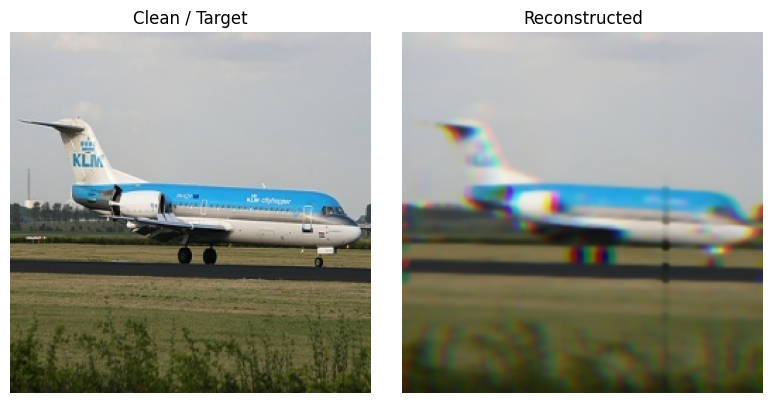

Similarity Score: 0.7010
------------------/------------------


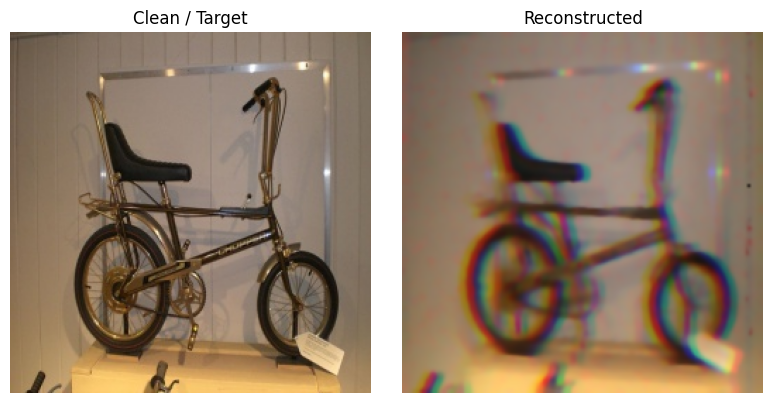

Similarity Score: 0.6606
------------------/------------------
Mean Validation Score: 0.6808


In [246]:
def compare_and_score(clean, reconstructed):
    """
    Visualizes side-by-side comparison and calculates SSIM score.
    """
    fig = plt.figure(figsize=(8, 4), layout='tight')
    ax1, ax2 = fig.subplots(1, 2)
    
    ax1.imshow(clean)
    ax1.set_title("Clean / Target")
    ax1.axis('off')
    
    ax2.imshow(reconstructed)
    ax2.set_title("Reconstructed")
    ax2.axis('off')
    
    plt.show()

    # Calculate Structural Similarity Index
    score = ssim(np.array(clean), np.array(reconstructed), channel_axis=2)
    print(f'Similarity Score: {score:.4f}')
    print('------------------/------------------')
    return score

# --- Local Validation Loop ---
validation_scores = []
for i in range(2):
    noisy_img = cv2.imread(f'data/images/train_data/image_{i}.jpg')
    noisy_img = cv2.cvtColor(noisy_img, cv2.COLOR_BGR2RGB)
    target_img = cv2.imread(f'data/images/validation_data/image_{i}.jpg')
    target_img = cv2.cvtColor(target_img, cv2.COLOR_BGR2RGB)

    # Run your custom reconstruction function
    reconstructed = reconstruct_image(noisy_img)
    
    # Check results
    score = compare_and_score(target_img, reconstructed)
    validation_scores.append(score)

print(f'Mean Validation Score: {np.mean(validation_scores):.4f}')

In [247]:
df_train = pd.read_csv("train_data.csv")
df_test = pd.read_csv("test_data.csv")

df_train.head()

,ID,path,label
0,802,data/images/train_data/image_0.jpg,aeroplane
1,27,data/images/train_data/image_1.jpg,bicycle
2,723,data/images/train_data/image_2.jpg,cat
3,696,data/images/train_data/image_3.jpg,bird
4,289,data/images/train_data/image_4.jpg,cat


In [248]:
from sklearn.preprocessing import LabelEncoder
enc = LabelEncoder()
df_train.label = enc.fit_transform(df_train.label)
df_train.head()

,ID,path,label
0,802,data/images/train_data/image_0.jpg,0
1,27,data/images/train_data/image_1.jpg,1
2,723,data/images/train_data/image_2.jpg,5
3,696,data/images/train_data/image_3.jpg,2
4,289,data/images/train_data/image_4.jpg,5


In [249]:
import torch

epochs = 20
learning_rate = 0.003
batch_size = 32

device = torch.device("cuda")
device

device(type='cuda')

In [250]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

train_transform = T.Compose([
    T.ToPILImage(),
    T.Resize(96),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = T.Compose([
    T.ToPILImage(),
    T.Resize(96),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class MyDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        filepath = self.df.path.iloc[idx]
        img = cv2.imread(filepath)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = reconstruct_image(img)
        img = self.transform(img)
        label = torch.tensor(self.df.label.iloc[idx], dtype=torch.long)
        return img, label

from sklearn.model_selection import train_test_split
df_1, df_2 = train_test_split(df_train, test_size=0.2, random_state=42)
df_1 = df_1.reset_index()
df_2 = df_2.reset_index()

train_dataset = MyDataset(df_1, transform=train_transform)
train_loader = DataLoader(train_dataset, batch_size=batch_size)

test_dataset = MyDataset(df_2, transform=test_transform)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

In [256]:
import torch.nn as nn

class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 16, 3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(16, 32, 3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.LazyLinear(32),
            nn.ReLU(),
            nn.Linear(32, 7)
        )
    def forward(self, x):
        x = self.net(x)
        return x

model = Net().to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-3)

model

Net(
  (net): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): AdaptiveAvgPool2d(output_size=1)
    (7): Flatten(start_dim=1, end_dim=-1)
    (8): LazyLinear(in_features=0, out_features=32, bias=True)
    (9): ReLU()
    (10): Linear(in_features=32, out_features=7, bias=True)
  )
)

In [252]:
def train(model, device, train_loader, criterion, optimizer, epoch):
    model.train()
    total_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model(inputs), labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch}, Training Loss: {total_loss / len(train_loader):.4f}")


def test(model, device, test_loader, criterion):
    model.eval()
    test_loss = 0.0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            test_loss += loss.item()
    print(f'Test Loss: {test_loss / len(test_loader):.4f}')

In [253]:
for epoch in range(1, epochs+1):
    train(model, device, train_loader, criterion, optimizer, epoch)
    test(model, device, test_loader, criterion)

Epoch 1, Training Loss: 1.8918
Test Loss: 1.7820
Epoch 2, Training Loss: 1.7508
Test Loss: 1.7204
Epoch 3, Training Loss: 1.6957
Test Loss: 1.6605
Epoch 4, Training Loss: 1.6396
Test Loss: 1.6415
Epoch 5, Training Loss: 1.5939
Test Loss: 1.6232
Epoch 6, Training Loss: 1.5674
Test Loss: 1.6385
Epoch 7, Training Loss: 1.5426
Test Loss: 1.6196
Epoch 8, Training Loss: 1.5206
Test Loss: 1.6264
Epoch 9, Training Loss: 1.5007
Test Loss: 1.6372
Epoch 10, Training Loss: 1.4864
Test Loss: 1.6271
Epoch 11, Training Loss: 1.4724
Test Loss: 1.6192
Epoch 12, Training Loss: 1.4556
Test Loss: 1.6132
Epoch 13, Training Loss: 1.4453
Test Loss: 1.6106
Epoch 14, Training Loss: 1.4314
Test Loss: 1.5900
Epoch 15, Training Loss: 1.4140
Test Loss: 1.5762
Epoch 16, Training Loss: 1.4011
Test Loss: 1.5681
Epoch 17, Training Loss: 1.3837
Test Loss: 1.5508
Epoch 18, Training Loss: 1.3671
Test Loss: 1.5614
Epoch 19, Training Loss: 1.3605
Test Loss: 1.5385
Epoch 20, Training Loss: 1.3518
Test Loss: 1.5163
Epoch 21,

In [254]:
final_transform = T.Compose([
    T.ToPILImage(),
    T.Resize(96),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class FinalDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        path = self.df.path.iloc[idx]
        img = cv2.imread(path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = reconstruct_image(img)
        img = self.transform(img)
        return img

def make_prediction(input_df): 
    # Task 2 placeholder (Classification)
    df = input_df.copy()
    final_dataset = FinalDataset(df, transform=final_transform)
    final_loader = DataLoader(final_dataset, batch_size=batch_size)

    model.eval()
    preds = []
    with torch.no_grad():
        for inputs in final_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            predicted = torch.argmax(outputs, dim=1)
            preds.extend(predicted.cpu().numpy())
    preds = enc.inverse_transform(preds)
    return preds

In [255]:
def generate_submission_file():
    """
    Compiles predictions for all subtasks into the required CSV format.
    """
    submission_rows = []
    test_df = pd.read_csv('test_data.csv')
 
    print("Processing Subtask 1: Mean Difference...")
    # (1, 1, Answer) format
    task1_result = compute_mean_difference(test_df)
    submission_rows.append((1, 1, task1_result))

    print("Processing Subtask 2: Classification...")
    preds = make_prediction(test_df)
    for idx, row in test_df.iterrows():
        # (2, ID, Label) format
        submission_rows.append((2, row['ID'], preds[idx])) 
 
    # Create and save DF
    submission_df = pd.DataFrame(submission_rows, columns=['subtaskID', 'datapointID', 'answer'])
    submission_df.to_csv('submission.csv', index=False)
    
    print("submission.csv created successfully.")
    return submission_df
 
submission = generate_submission_file()

Processing Subtask 1: Mean Difference...
Processing Subtask 2: Classification...
submission.csv created successfully.
